# BÀI TẬP NÂNG CAO: Mô hình SARIMA trên chuỗi AirPassengers

**Dữ liệu (dataset 2):** AirPassengers, số hành khách hàng không quốc tế mỗi tháng (đơn vị: nghìn người), từ 01/1949 đến 12/1960, gồm 144 quan sát (12 năm × 12 tháng).
**Nguồn:** [airline-passengers.csv trên GitHub](https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv). Đây là bộ dữ liệu kinh điển của Box và Jenkins, thường dùng để minh họa chuỗi có xu hướng và mùa vụ.
**Chu kỳ mùa vụ:** hằng tháng, s = 12.

**Yêu cầu**
1. Vẽ chuỗi thời gian và nhận diện mùa vụ.
2. Kiểm định ADF trên chuỗi gốc (kỳ vọng: không dừng).
3. Sai phân thường và sai phân mùa vụ.
4. Dùng ACF/PACF để xác định (p, q, P, Q).
5. Fit mô hình SARIMA.
6. Dự báo và đánh giá bằng MAE, RMSE.
7. So sánh với ARIMA.

**Câu hỏi cần trả lời**
- Chuỗi có xu hướng và mùa vụ không? Mùa vụ có chu kỳ bao nhiêu và rơi vào tháng nào?
- Vì sao cần cả sai phân thường (d = 1) lẫn sai phân mùa vụ (D = 1)?
- ACF/PACF gợi ý bậc (p, q, P, Q) nào?
- Phần dư của SARIMA đã là nhiễu trắng chưa?
- SARIMA tốt hơn ARIMA bao nhiêu, và vì sao?

**Thiết kế đánh giá:** tập test là 12 tháng cuối (năm 1960); mọi mô hình chỉ fit trên tập train (132 tháng đầu, 01/1949 đến 12/1959). Tập test chỉ dùng để đánh giá, không dùng để chọn bậc mô hình.

## Chuẩn bị thư viện và dữ liệu

In [30]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, acf, pacf

DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
SEASONAL_PERIOD = 12
TEST_MONTHS = 12
ALPHA = 0.05

data = pd.read_csv(DATA_URL, parse_dates=["Month"])
data = data.set_index("Month").sort_index()
data.index = pd.DatetimeIndex(data.index, freq="MS")
passengers = data["Passengers"].astype(float)

if passengers.index.has_duplicates:
    raise ValueError("Dữ liệu có tháng bị lặp.")
if passengers.isna().any():
    raise ValueError("Dữ liệu có giá trị thiếu; hãy kiểm tra lại nguồn dữ liệu.")
if not passengers.index.is_monotonic_increasing:
    raise ValueError("Thời gian phải được sắp xếp tăng dần.")

print(f"Số quan sát: {len(passengers)}")
print(f"Khoảng thời gian: {passengers.index.min():%Y-%m} đến {passengers.index.max():%Y-%m}")
print(f"Tần suất: {passengers.index.freqstr}")
print("\nNăm dòng đầu:")
print(data.head().to_string())

Số quan sát: 144
Khoảng thời gian: 1949-01 đến 1960-12
Tần suất: MS

Năm dòng đầu:
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


In [31]:
import matplotlib.dates as mdates

# Hàm phụ cho các biểu đồ: chia rõ từng năm + đường Mean/Max/Min
years = sorted(passengers.index.year.unique())
YEAR_COLORS = dict(zip(years, plt.cm.turbo(np.linspace(0.05, 0.95, len(years)))))


def year_bands(ax, series):
    """Kẻ vạch chấm mảnh ngăn từng năm (tại ngày 1/1)."""
    for yr in years:
        ax.axvline(pd.Timestamp(f"{yr}-01-01"), color="0.55", lw=0.7, ls=":")
    ax.set_xlim(series.index[0] - pd.Timedelta(days=15), series.index[-1] + pd.Timedelta(days=45))


def set_year_axis(ax):
    """Trục x ghi số năm, mỗi năm một nhãn."""
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def stat_lines(ax, series, zero_ref=False):
    """Vẽ đường Mean / Max / Min, đánh dấu điểm Max, Min trên đường."""
    s = series.dropna()
    ax.axhline(s.mean(), color="#e08a00", ls="--", lw=1.4, label=f"Mean = {s.mean():.1f}")
    ax.axhline(s.max(), color="#d62728", ls="--", lw=1.2, label=f"Max = {s.max():.1f} ({s.idxmax():%m/%Y})")
    ax.axhline(s.min(), color="#2ca02c", ls="--", lw=1.2, label=f"Min = {s.min():.1f} ({s.idxmin():%m/%Y})")
    ax.scatter([s.idxmax()], [s.max()], color="#d62728", s=70, zorder=5, edgecolor="k")
    ax.scatter([s.idxmin()], [s.min()], color="#2ca02c", s=70, zorder=5, edgecolor="k")
    if zero_ref:
        ax.axhline(0, color="k", lw=0.8)

## 1. Vẽ chuỗi thời gian → nhận diện mùa vụ

**Yêu cầu**
- Tính thống kê mô tả (Min, Max, Mean) và vẽ chuỗi thời gian.
- Dùng seasonal plot, heatmap tháng × năm và phân rã STL để nhận diện xu hướng và mùa vụ.

**Câu hỏi cần trả lời**
- Chuỗi có xu hướng không?
- Chuỗi có mùa vụ không? Chu kỳ bao nhiêu tháng, đỉnh và đáy rơi vào tháng nào?
- Biên độ mùa vụ có thay đổi theo thời gian không?

### 1.1. Thống kê mô tả và line plot
Biểu đồ có ba đường ngang **Mean, Max, Min** (điểm Max, Min được đánh dấu trên đường) và vạch chấm dọc ngăn từng năm.

Thống kê mô tả:
count    144.00
mean     280.30
std      119.97
min      104.00
25%      180.00
50%      265.50
75%      360.50
max      622.00

Số giá trị thiếu: 0
Tổng lượng hành khách trong dữ liệu (nghìn): 40,363


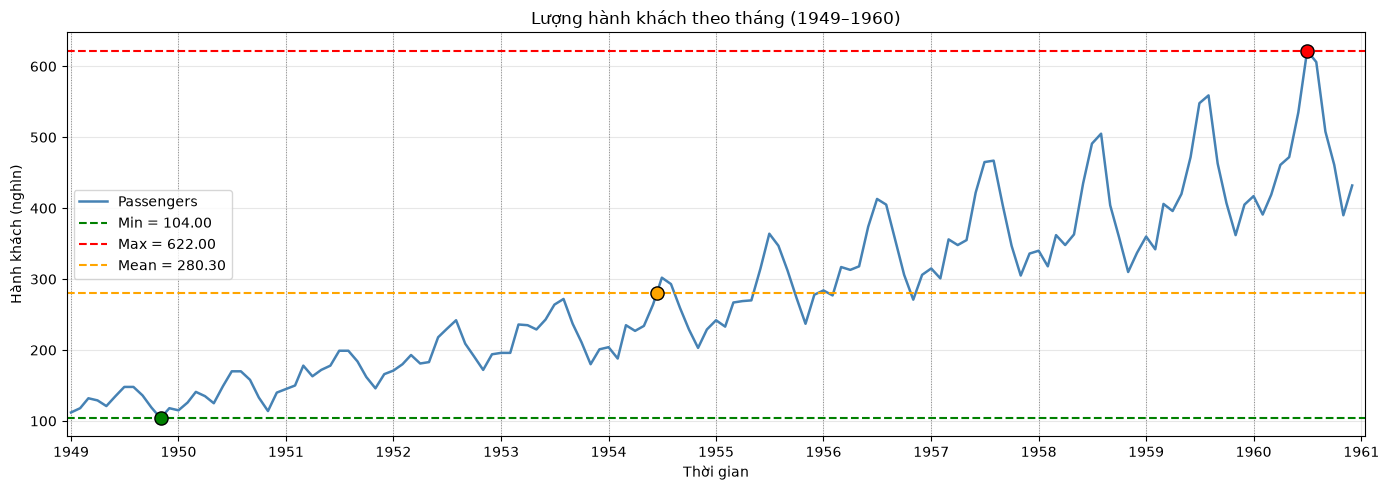

Min  = 104.00
Max  = 622.00
Mean = 280.30


In [32]:
print("Thống kê mô tả:")
print(data["Passengers"].describe().round(2).to_string())
print(f"\nSố giá trị thiếu: {int(data['Passengers'].isna().sum())}")
print(f"Tổng lượng hành khách trong dữ liệu (nghìn): {passengers.sum():,.0f}")

# Tính Min, Max, Mean
min_val = passengers.min()
max_val = passengers.max()
mean_val = passengers.mean()

# Xác định thời điểm đạt Min và Max
min_date = passengers.idxmin()
max_date = passengers.idxmax()

fig, ax = plt.subplots(figsize=(14, 5))
year_bands(ax, passengers)

# Vẽ chuỗi gốc
ax.plot(passengers.index, passengers,
        color='steelblue', linewidth=1.8, label='Passengers')

# Vẽ 3 đường ngang
ax.axhline(min_val, color='green', linestyle='--',
           linewidth=1.5, label=f'Min = {min_val:.2f}')

ax.axhline(max_val, color='red', linestyle='--',
           linewidth=1.5, label=f'Max = {max_val:.2f}')

ax.axhline(mean_val, color='orange', linestyle='--',
           linewidth=1.5, label=f'Mean = {mean_val:.2f}')

# Đánh dấu Min và Max ngay trên đường Line Plot
ax.scatter(min_date, min_val, color='green',
           s=90, zorder=5, edgecolor='black')

ax.scatter(max_date, max_val, color='red',
           s=90, zorder=5, edgecolor='black')

# Tìm vị trí đường Line Plot cắt mức Mean
# Sử dụng nội suy tuyến tính giữa hai quan sát liên tiếp
values = passengers.to_numpy()
crossings = [
    i for i in range(len(values) - 1)
    if (values[i] - mean_val) * (values[i + 1] - mean_val) <= 0
    and values[i] != values[i + 1]
]

if crossings:
    i = crossings[0]
    ratio = (mean_val - values[i]) / (values[i + 1] - values[i])
    mean_date = passengers.index[i] + (
        passengers.index[i + 1] - passengers.index[i]
    ) * ratio

    ax.scatter(mean_date, mean_val, color='orange',
               s=90, zorder=5, edgecolor='black')

ax.set(
    title="Lượng hành khách theo tháng (1949–1960)",
    xlabel="Thời gian",
    ylabel="Hành khách (nghìn)"
)

ax.grid(alpha=0.3)
ax.legend()
set_year_axis(ax)
plt.tight_layout()
plt.show()

print(f"Min  = {min_val:.2f}")
print(f"Max  = {max_val:.2f}")
print(f"Mean = {mean_val:.2f}")

**Nhận xét 1.1:**
- **Thống kê:** Mean = 280,30; độ lệch chuẩn = 119,97; trung vị = 265,5; không có giá trị thiếu. **Min = 104** (11/1949), **Max = 622** (07/1960); tổng cộng 40.363 nghìn hành khách.
- **Xu hướng:** chuỗi tăng gần như liên tục. Trung bình mỗi năm tăng từ 126,7 (1949) lên 476,2 (1960), gấp khoảng 3,8 lần; năm nào cũng cao hơn năm trước (tăng chậm nhất là 1958, chỉ +3,4%).
- **Mùa vụ:** các đỉnh lặp lại mỗi năm vào mùa hè, các đáy vào cuối năm.
- **Biên độ tăng dần:** khoảng chênh Max − Min trong cùng một năm tăng từ 44 (1949: từ 104 đến 148) lên 232 (1960: từ 390 đến 622). Dao động mùa vụ vì vậy **lớn dần theo mức của chuỗi**. Độ lệch chuẩn tổng (119,97) lớn chủ yếu do xu hướng tăng, không chỉ do mùa vụ.

### 1.2. Seasonal plot và heatmap tháng × năm
- **Seasonal plot:** mỗi đường là một năm (12 năm, 12 màu khác nhau); đường đen nét đứt là **trung bình theo tháng**.
- **Heatmap:** mỗi cột là một năm, mỗi hàng là một tháng. Ô viền xanh dương là **Max**, ô viền xanh lá là **Min**; dưới mỗi cột ghi Min / Mean / Max của năm đó, bên phải mỗi hàng ghi Mean của tháng đó.

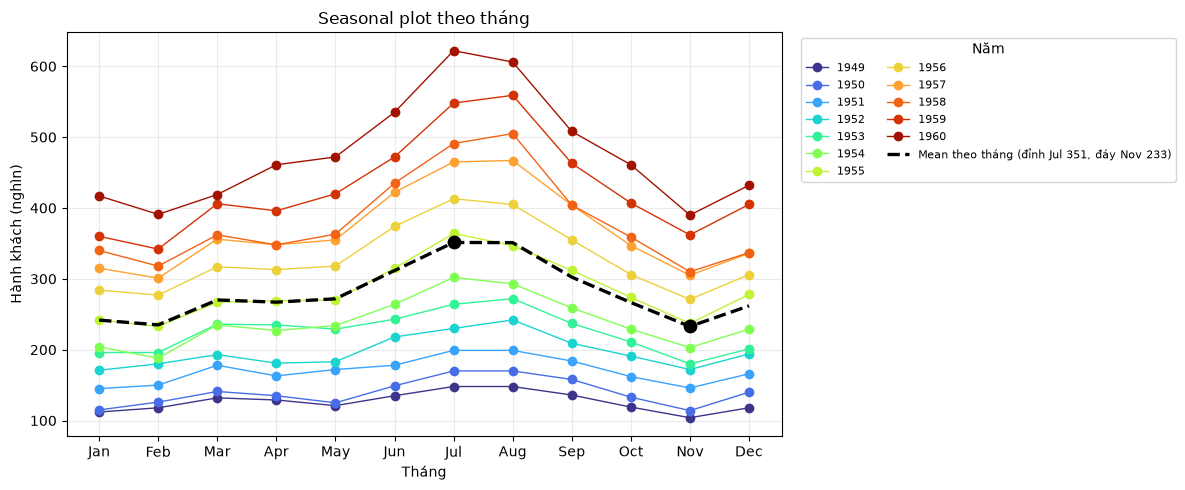

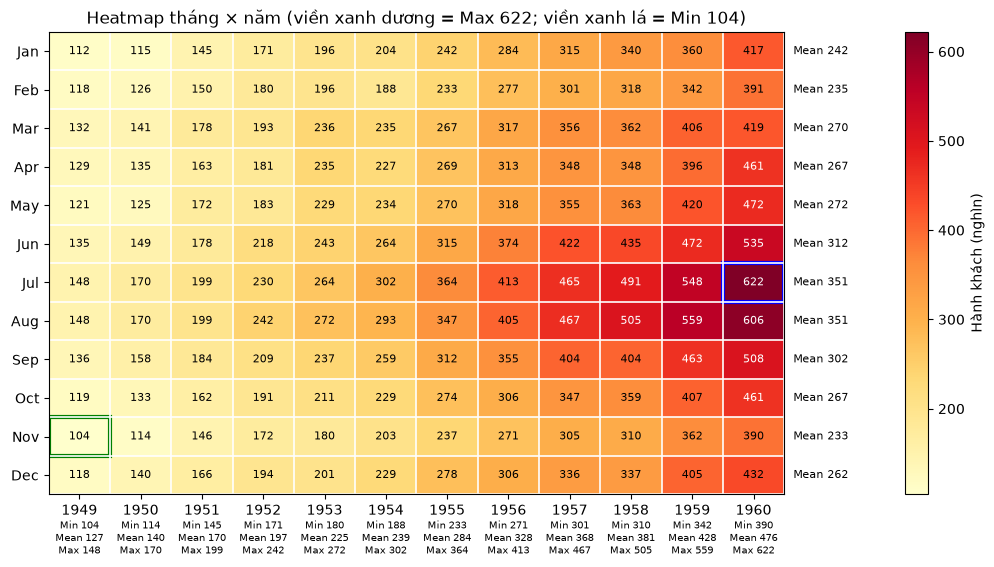


Trung bình tháng cao nhất: Jul (351.3)
Trung bình tháng thấp nhất: Nov (232.8)
Trung bình năm đầu/cuối: 126.7 (1949) / 476.2 (1960)
Thay đổi từ đầu đến cuối chuỗi: 285.7%


In [33]:
seasonal_data = data.assign(
    Year=data.index.year,
    Month_num=data.index.month,
)
seasonal_table = seasonal_data.pivot(index="Month_num", columns="Year", values="Passengers")
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Seasonal plot: mỗi năm một màu riêng + đường trung bình theo tháng
fig, ax = plt.subplots(figsize=(12, 5))
for year in seasonal_table.columns:
    ax.plot(range(1, 13), seasonal_table[year], marker="o", linewidth=1,
            color=YEAR_COLORS[year], label=str(year))
mm = seasonal_table.mean(axis=1)
ax.plot(range(1, 13), mm, color="k", lw=2.4, ls="--",
        label=f"Mean theo tháng (đỉnh {month_labels[mm.idxmax()-1]} {mm.max():.0f}, đáy {month_labels[mm.idxmin()-1]} {mm.min():.0f})")
ax.scatter([mm.idxmax(), mm.idxmin()], [mm.max(), mm.min()], color="k", s=80, zorder=6)
ax.set_xticks(range(1, 13), month_labels)
ax.set(title="Seasonal plot theo tháng", xlabel="Tháng", ylabel="Hành khách (nghìn)")
ax.grid(alpha=0.25)
ax.legend(title="Năm", bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# Heatmap tháng × năm, kèm Min / Mean / Max từng năm (dưới cột) và Mean từng tháng (bên phải)
fig, ax = plt.subplots(figsize=(13, 6.8))
vals = seasonal_table.values
image = ax.imshow(vals, aspect="auto", origin="upper", cmap="YlOrRd")
ax.set_xticks(range(len(years)), years)
ax.set_yticks(range(12), month_labels)
ax.set_xticks(np.arange(-0.5, len(years), 1), minor=True)
ax.set_yticks(np.arange(-0.5, 12, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", length=0)
for i in range(12):
    for j in range(len(years)):
        ax.text(j, i, f"{vals[i, j]:.0f}", ha="center", va="center", fontsize=8,
                color="white" if vals[i, j] > 450 else "black")
for (i, j), c in ((np.unravel_index(vals.argmax(), vals.shape), "blue"),
                  (np.unravel_index(vals.argmin(), vals.shape), "green")):
    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=c, lw=3))
for j, yr in enumerate(years):
    col = seasonal_table[yr]
    ax.text(j, 12.15, f"Min {col.min():.0f}\nMean {col.mean():.0f}\nMax {col.max():.0f}",
            ha="center", va="top", fontsize=7.5, clip_on=False)
for i in range(12):
    ax.text(len(years) - 0.35, i, f"Mean {seasonal_table.iloc[i].mean():.0f}",
            ha="left", va="center", fontsize=8, clip_on=False)
ax.set(title=f"Heatmap tháng × năm (viền xanh dương = Max {vals.max():.0f}; viền xanh lá = Min {vals.min():.0f})")
fig.colorbar(image, ax=ax, label="Hành khách (nghìn)", pad=0.12)
fig.subplots_adjust(bottom=0.2, right=0.9)
plt.show()

monthly_mean = seasonal_data.groupby("Month_num")["Passengers"].mean()
annual_mean = seasonal_data.groupby("Year")["Passengers"].mean()
print(f"\nTrung bình tháng cao nhất: {month_labels[monthly_mean.idxmax() - 1]} ({monthly_mean.max():.1f})")
print(f"Trung bình tháng thấp nhất: {month_labels[monthly_mean.idxmin() - 1]} ({monthly_mean.min():.1f})")
print(f"Trung bình năm đầu/cuối: {annual_mean.iloc[0]:.1f} ({annual_mean.index[0]}) / {annual_mean.iloc[-1]:.1f} ({annual_mean.index[-1]})")
print(f"Thay đổi từ đầu đến cuối chuỗi: {(passengers.iloc[-1] / passengers.iloc[0] - 1) * 100:.1f}%")

**Nhận xét 1.2:**
- **Seasonal plot:** 12 đường có **cùng hình dạng** và gần như không cắt nhau, xếp chồng lên theo thứ tự năm (năm sau cao hơn năm trước). Hình dạng lặp lại cho thấy **mùa vụ ổn định**, việc xếp tầng cho thấy **xu hướng tăng**.
- **Trung bình theo tháng:** thấp nhất ở tháng 2 (235,0), tăng từ tháng 6, **cao nhất ở tháng 7 (351,3) và tháng 8 (351,1)**, giảm dần và chạm **đáy ở tháng 11 (232,8)**, rồi nhích lên ở tháng 12 (261,8). Tháng 7 cao hơn tháng 11 khoảng 1,5 lần.
- **Heatmap:** màu đậm dần từ trái sang phải (theo năm) là xu hướng tăng; hai hàng tháng 7 và 8 luôn đậm nhất mỗi cột là mùa vụ. Ô **Max = 622** nằm ở tháng 7/1960, ô **Min = 104** ở tháng 11/1949. Trung bình năm ghi dưới cột tăng từ 127 (1949) lên 476 (1960).

### 1.3. Phân rã STL: xu hướng, mùa vụ và phần dư
Chuỗi được tách thành ba thành phần (chu kỳ s = 12, bản `robust`). Mỗi thành phần có đường Mean / Max / Min riêng.

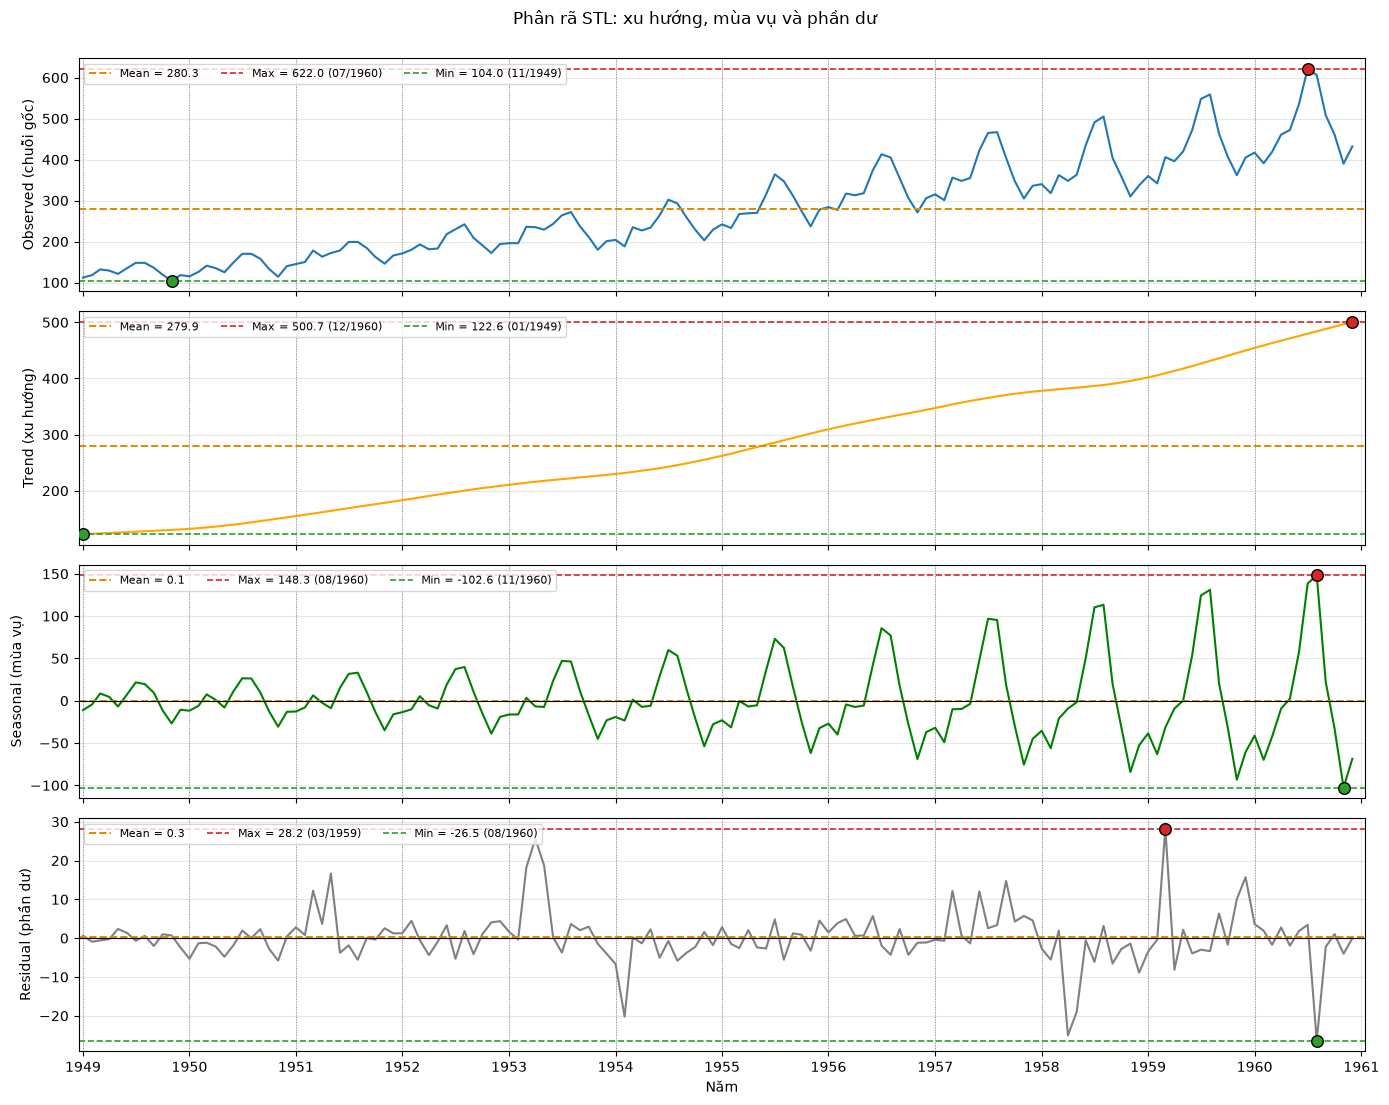

In [34]:
stl_result = STL(passengers, period=SEASONAL_PERIOD, robust=True).fit()
stl_parts = [("Observed (chuỗi gốc)", stl_result.observed, "#1f77b4"),
             ("Trend (xu hướng)", stl_result.trend, "orange"),
             ("Seasonal (mùa vụ)", stl_result.seasonal, "green"),
             ("Residual (phần dư)", stl_result.resid, "gray")]

fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for k, (ax, (name, s, c)) in enumerate(zip(axes, stl_parts)):
    year_bands(ax, s)
    ax.plot(s, color=c)
    stat_lines(ax, s, zero_ref=(k >= 2))
    ax.set_ylabel(name)
    ax.legend(loc="upper left", fontsize=8, ncol=3)
    ax.grid(alpha=0.3)
    set_year_axis(ax)
axes[-1].set_xlabel("Năm")
fig.suptitle("Phân rã STL: xu hướng, mùa vụ và phần dư", y=1.00)
plt.tight_layout()
plt.show()

**Nhận xét 1.3:**
- **Trend (xu hướng):** tăng đều từ 122,6 (01/1949) lên 500,7 (12/1960); đường cong trơn, không có đoạn đảo chiều.
- **Seasonal (mùa vụ):** dao động quanh 0 (Mean = 0,1) theo chu kỳ 12 tháng, có đỉnh cao nhất +148,3 (08/1960) và đáy thấp nhất −102,6 (11/1960). Biên độ mùa vụ **lớn dần**: năm 1949 chỉ khoảng ±25, đến 1960 khoảng từ −100 đến +150.
- **Residual (phần dư):** nằm trong khoảng −26,5 (08/1960) đến +28,2 (03/1959), nhỏ so với xu hướng và mùa vụ, Mean = 0,3 ≈ 0. Vẫn có vài điểm lệch lớn, như 03/1959 và 08/1960.

### Nhận xét mục 1
**Chuỗi có xu hướng không?** **Có**: tăng mạnh và đều (trung bình năm gấp khoảng 3,8 lần sau 11 năm).

**Chuỗi có mùa vụ không?** **Có**, chu kỳ **12 tháng** (s = 12). Đỉnh vào tháng 7 và 8, đáy vào tháng 11.

**Biên độ mùa vụ có đổi theo thời gian không?** **Có**, biên độ tăng cùng mức của chuỗi (khoảng chênh trong năm từ 44 lên 232). Đây là dấu hiệu của mùa vụ dạng **nhân**. Bài này không lấy log mà xử lý bằng sai phân theo gợi ý của đề.

**Kết luận:** trung bình thay đổi theo thời gian (xu hướng) và phương sai cũng tăng dần, nên chuỗi nhiều khả năng **không dừng**. Mục 2 kiểm tra điều này bằng kiểm định ADF.

## 2. ADF chuỗi gốc → kiểm tra tính không dừng

**Yêu cầu**
- Thực hiện kiểm định ADF trên chuỗi gốc: ADF statistic, p-value, kết luận dừng / không dừng.

**Câu hỏi cần trả lời**
- H₀ của ADF là gì?
- p-value cho biết điều gì?
- Chuỗi gốc có dừng không?

### 2.1. Giả thuyết và quy tắc quyết định
- **H₀:** chuỗi có nghiệm đơn vị (**không dừng**).
- **H₁:** chuỗi dừng.
- **Quy tắc:** p-value ≤ 0,05 thì bác bỏ H₀, kết luận chuỗi dừng. p-value > 0,05 thì chưa đủ bằng chứng bác bỏ H₀, chuỗi không dừng.
- **Cách đọc thứ hai:** nếu ADF statistic **nhỏ hơn** giá trị tới hạn ở mức 5% thì chuỗi dừng.

### 2.2. Kết quả ADF trên chuỗi gốc

In [35]:
def run_adf(series):
    result = adfuller(series.dropna(), autolag="AIC")
    return {"ADF statistic": result[0], "p-value": result[1], "lags": result[2], "observations": result[3]}


adf_original = run_adf(passengers)
print(f"ADF statistic chuỗi gốc: {adf_original['ADF statistic']:.6f}")
print(f"p-value chuỗi gốc: {adf_original['p-value']:.6f}")
print(f"Số độ trễ: {adf_original['lags']}; số quan sát dùng trong kiểm định: {adf_original['observations']}")
print("Kết luận:", "bác bỏ H₀ ở mức 5%." if adf_original["p-value"] < ALPHA else "chưa đủ bằng chứng bác bỏ H₀; chuỗi có dấu hiệu không dừng.")

ADF statistic chuỗi gốc: 0.815369
p-value chuỗi gốc: 0.991880
Số độ trễ: 13; số quan sát dùng trong kiểm định: 130
Kết luận: chưa đủ bằng chứng bác bỏ H₀; chuỗi có dấu hiệu không dừng.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_23268\3849454129.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")


**Nhận xét 2.2:**

| Chỉ số | Giá trị |
|---|---|
| ADF statistic | 0,8154 |
| p-value | 0,9919 |
| Số độ trễ dùng (chọn theo AIC) | 13 |
| Số quan sát dùng trong kiểm định | 130 |
| Giá trị tới hạn 5% | −2,884 |

### Nhận xét mục 2
**H₀ của ADF là gì?** Chuỗi có nghiệm đơn vị, tức **không dừng**.

**p-value cho biết điều gì?** Là mức bằng chứng chống lại H₀: nếu H₀ đúng thì khả năng gặp kết quả như đã quan sát (hoặc cực đoan hơn) lớn hay nhỏ. p-value càng nhỏ thì càng có cơ sở bác bỏ H₀. Ở đây p-value = 0,9919, **rất lớn so với 0,05**.

**Chuỗi gốc có dừng không?** **Không dừng.** Chưa đủ bằng chứng để bác bỏ H₀. ADF statistic (0,8154) cũng nằm **bên phải** giá trị tới hạn 5% (−2,884), tức không thỏa điều kiện dừng. Kết quả này **khớp với mục 1**: trung bình tăng theo thời gian và biên độ dao động lớn dần. Vì vậy cần **sai phân** trước khi xây dựng mô hình.

## 3. Sai phân thường + mùa vụ

**Yêu cầu**
- Sai phân thường (loại xu hướng) và sai phân mùa vụ (loại mùa vụ), rồi kiểm định ADF lại.

**Câu hỏi cần trả lời**
- Sai phân thường, sai phân mùa vụ hay kết hợp cả hai thì chuỗi mới dừng?
- Vì sao cần cả d = 1 và D = 1?

**Cấu hình theo gợi ý của đề:** d = 1 (loại xu hướng), D = 1 (loại mùa vụ), s = 12.
- Sai phân thường: yₜ − yₜ₋₁
- Sai phân mùa vụ: yₜ − yₜ₋₁₂
- Sai phân kết hợp: (yₜ − yₜ₋₁) − (yₜ₋₁₂ − yₜ₋₁₃)

### 3.1. ADF trên các chuỗi sai phân và đồ thị
Bảng bên dưới là kết quả ADF của 4 chuỗi; hình có 4 panel tương ứng, mỗi panel có đường Mean / Max / Min, độ lệch chuẩn (Std) và vạch ngăn từng năm.

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_23268\3849454129.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_23268\3849454129.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2326

                                   ADF statistic   p-value  lags  observations  Dừng ở mức 5%
Chuỗi                                                                                        
Chuỗi gốc                               0.815369  0.991880    13           130          False
Sai phân thường (d=1)                  -2.829267  0.054213    12           130          False
Sai phân mùa vụ (D=1, s=12)            -3.383021  0.011551     1           130           True
Sai phân kết hợp (d=1, D=1, s=12)     -15.595618  0.000000     0           130           True


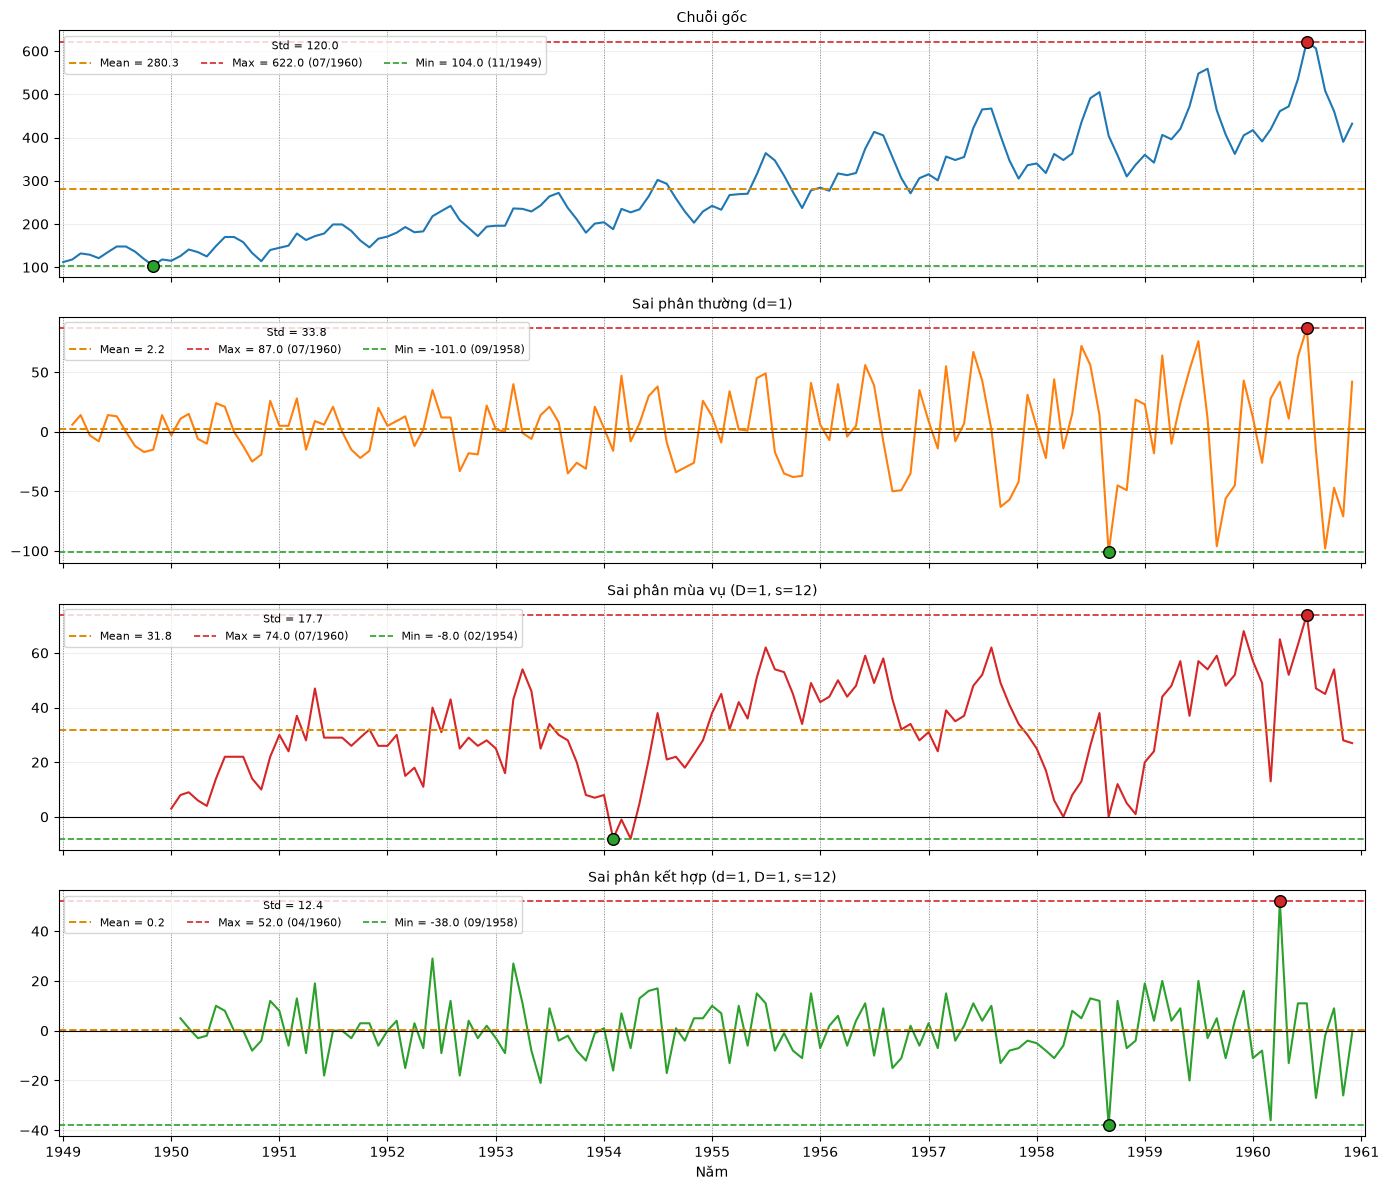


Diễn giải: p-value ADF nhỏ hơn 0,05 là bằng chứng chuỗi dừng theo kiểm định; đây không phải bảo đảm cho mọi cấu hình kiểm định.


In [36]:
difference_series = {
    "Chuỗi gốc": passengers,
    "Sai phân thường (d=1)": passengers.diff(1),
    "Sai phân mùa vụ (D=1, s=12)": passengers.diff(SEASONAL_PERIOD),
    "Sai phân kết hợp (d=1, D=1, s=12)": passengers.diff(1).diff(SEASONAL_PERIOD),
}

adf_rows = []
for label, series in difference_series.items():
    result = run_adf(series)
    adf_rows.append({"Chuỗi": label, **result, "Dừng ở mức 5%": result["p-value"] < ALPHA})
adf_table = pd.DataFrame(adf_rows).set_index("Chuỗi")
print(adf_table.round(6).to_string())

diff_colors = ["#1f77b4", "tab:orange", "tab:red", "tab:green"]
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for k, (ax, (name, s), c) in enumerate(zip(axes, difference_series.items(), diff_colors)):
    year_bands(ax, passengers)
    ax.plot(s, color=c, lw=1.5)
    stat_lines(ax, s, zero_ref=(k >= 1))
    ax.set_title(name, fontsize=10)
    ax.legend(loc="upper left", fontsize=8, ncol=3, title=f"Std = {s.dropna().std():.1f}", title_fontsize=8)
    ax.grid(alpha=0.2)
    set_year_axis(ax)
axes[-1].set_xlabel("Năm")
plt.tight_layout()
plt.show()

print("\nDiễn giải: p-value ADF nhỏ hơn 0,05 là bằng chứng chuỗi dừng theo kiểm định; đây không phải bảo đảm cho mọi cấu hình kiểm định.")

**Nhận xét 3.1:**

| Chuỗi | ADF statistic | p-value | Dừng ở mức 5%? | Mean | Std |
|---|---|---|---|---|---|
| Gốc | 0,8154 | 0,9919 | Không | 280,3 | 120,0 |
| Sai phân thường (d = 1) | −2,8293 | 0,0542 | Không (sát ngưỡng) | 2,2 | 33,8 |
| Sai phân mùa vụ (D = 1, s = 12) | −3,3830 | 0,0116 | Có | 31,8 | 17,7 |
| Kết hợp (d = 1, D = 1, s = 12) | −15,5956 | 1,86e-28 | Có | 0,2 | 12,4 |

- **Sai phân thường (d = 1):** xu hướng đã mất, chuỗi dao động quanh mức gần 0 (Mean = 2,2). Nhưng dao động theo chu kỳ 12 tháng vẫn còn và **lớn dần**: độ lệch chuẩn là 14,8 ở giai đoạn 1949–1950 và 52,7 ở giai đoạn 1959–1960. ADF cho p = 0,0542, **sát ngưỡng nhưng chưa dừng**.
- **Sai phân mùa vụ (D = 1):** loại được chu kỳ mùa vụ, ADF cho p = 0,0116 (dừng). Chuỗi này là chênh lệch giữa cùng một tháng của hai năm liên tiếp nên dao động quanh **+31,8** (trung bình mỗi tháng năm nay cao hơn năm trước khoảng 31,8 nghìn), tức vẫn mang dấu vết của xu hướng, chứ không quanh 0.
- **Kết hợp (d = 1, D = 1):** chuỗi dao động quanh 0 (Mean = 0,2), độ lệch chuẩn giảm từ 120,0 xuống 12,4, ADF statistic = −15,5956 và p ≈ 1,86e-28: **dừng rõ ràng nhất**. Vẫn còn vài điểm lệch lớn (04/1960: +52; 09/1958: −38), và biên độ tăng nhẹ về cuối (độ lệch chuẩn 9,7 ở 1950–1952 so với 17,3 ở 1958–1960) do mùa vụ dạng nhân.

### Nhận xét mục 3
**Sau sai phân, chuỗi đã dừng chưa?** Sai phân thường riêng lẻ **chưa dừng** (p = 0,0542, sát ngưỡng); sai phân mùa vụ riêng lẻ đạt ngưỡng (p = 0,0116) nhưng chuỗi còn lệch khỏi 0; **kết hợp d = 1 và D = 1 thì dừng rõ ràng** (p ≈ 1,86e-28).

**Vì sao cần cả d = 1 và D = 1?** Hai loại sai phân xử lý hai thành phần khác nhau:
- **d = 1** loại **xu hướng** (đưa trung bình về quanh 0).
- **D = 1 (s = 12)** loại **mùa vụ chu kỳ 12 tháng**.
Chuỗi AirPassengers có cả hai thành phần (mục 1), nên chỉ dùng một loại thì phần còn lại vẫn làm chuỗi kém ổn định (độ lệch chuẩn 33,8 và 17,7 so với 12,4 khi kết hợp). Cấu hình **d = 1, D = 1, s = 12** cũng là cấu hình đề bài gợi ý.

**Giới hạn:** ADF chỉ là một chẩn đoán. Sau khi fit mô hình, ta vẫn phải kiểm tra phần dư (mục 5). Cấu hình d = 1, D = 1, s = 12 được đưa sang mục 4 để xác định các bậc (p, q, P, Q) bằng ACF/PACF.

## 4. ACF/PACF → xác định (p, q, P, Q)

**Yêu cầu**
- Chia train/test theo thứ tự thời gian (test = 12 tháng cuối), vẽ ACF và PACF của chuỗi train đã sai phân (d = 1, D = 1, s = 12).
- Đề xuất các bậc (p, q, P, Q).

**Câu hỏi cần trả lời**
- ACF cắt cụt ở lag nào? PACF cắt cụt ở lag nào?
- Các lag mùa vụ (12, 24, 36) có nổi bật không?
- Gợi ý mô hình SARIMA(p, d, q)(P, D, Q)₁₂ nào?

ACF/PACF chỉ tính trên **tập train** đã sai phân, để các quan sát của tập test không ảnh hưởng đến việc chọn bậc mô hình. Vùng xanh là khoảng tin cậy 95%: lag nào vượt ra ngoài vùng này mới được xem là có ý nghĩa.

### 4.1. ACF và PACF của chuỗi train sau sai phân

Train: 1949-01 đến 1959-12 (132 tháng)
Test:  1960-01 đến 1960-12 (12 tháng)


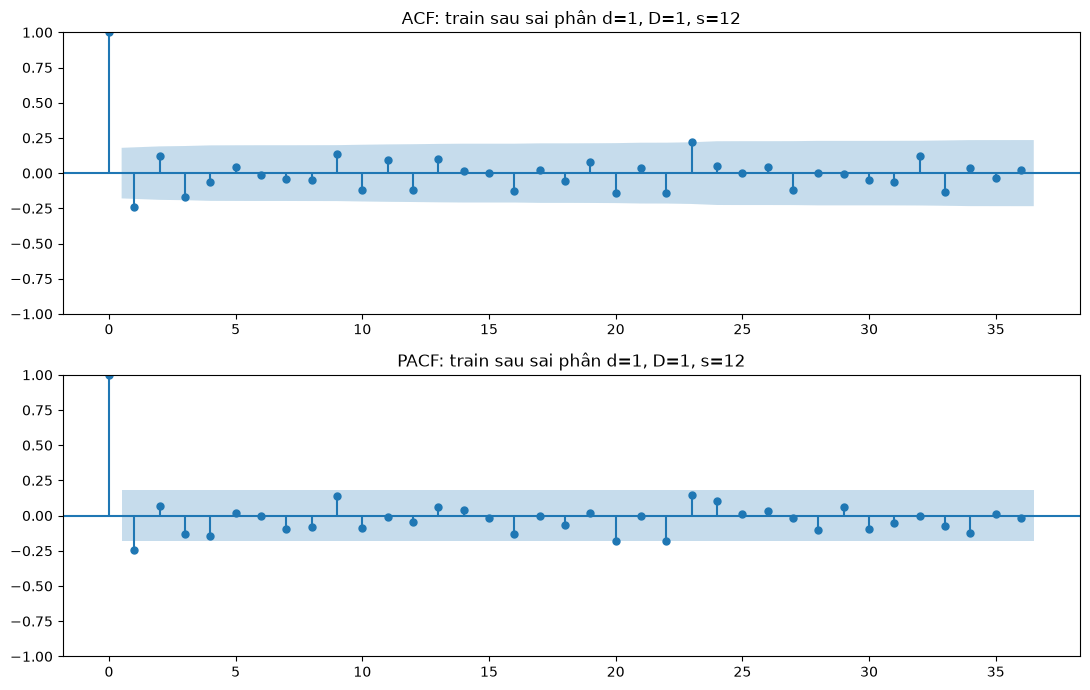


ACF/PACF tại một số lag:
       ACF   PACF
Lag              
1   -0.243 -0.243
2    0.123  0.068
12  -0.118 -0.047
13   0.097  0.061
24   0.050  0.106
36   0.024 -0.014
Ngưỡng tham khảo gần đúng 95%: ±0.180


In [37]:
train = passengers.iloc[:-TEST_MONTHS]
test = passengers.iloc[-TEST_MONTHS:]
train_diff = train.diff(1).diff(SEASONAL_PERIOD).dropna()

print(f"Train: {train.index[0]:%Y-%m} đến {train.index[-1]:%Y-%m} ({len(train)} tháng)")
print(f"Test:  {test.index[0]:%Y-%m} đến {test.index[-1]:%Y-%m} ({len(test)} tháng)")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
plot_acf(train_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF: train sau sai phân d=1, D=1, s=12")
plot_pacf(train_diff, lags=36, method="ywm", ax=axes[1])
axes[1].set_title("PACF: train sau sai phân d=1, D=1, s=12")
plt.tight_layout()
plt.show()

acf_values = acf(train_diff, nlags=36)
pacf_values = pacf(train_diff, nlags=36, method="ywm")
key_lags = [1, 2, 12, 13, 24, 36]
correlation_table = pd.DataFrame(
    {"ACF": [acf_values[lag] for lag in key_lags], "PACF": [pacf_values[lag] for lag in key_lags]},
    index=key_lags,
)
correlation_table.index.name = "Lag"
print("\nACF/PACF tại một số lag:")
print(correlation_table.round(3).to_string())
print(f"Ngưỡng tham khảo gần đúng 95%: ±{1.96 / np.sqrt(len(train_diff)):.3f}")

ACF/PACF là công cụ tham khảo, không xác định duy nhất bậc mô hình. ACF/PACF sau sai phân giúp đề xuất các bậc thường và mùa vụ; ở bước 5 sẽ thử `p=0`, `q=1`, `P=0` với `Q=0` hoặc `Q=1`, giữ `d=1`, `D=1`, `s=12`. Chọn SARIMA theo AIC trên train; ARIMA không mùa vụ sẽ được fit ở bước 7 để so sánh.

**Nhận xét 4.1:** Chuỗi train sau sai phân có 119 quan sát, ngưỡng tham khảo ±0,180.

| Lag | 1 | 2 | 12 | 13 | 24 | 36 |
|---|---|---|---|---|---|---|
| ACF | −0,243 | 0,123 | −0,118 | 0,097 | 0,050 | 0,024 |
| PACF | −0,243 | 0,068 | −0,047 | 0,061 | 0,106 | −0,014 |

- **Lag 1** là lag nổi bật duy nhất ở phần thường: cả ACF và PACF đều bằng −0,243 và vượt ngưỡng.
- Một vài lag lẻ khác chạm hoặc vượt nhẹ vùng tin cậy (ACF lag 23; PACF lag 20 và 22). Chúng nằm rải rác, **không rơi vào bội của 12**, và khi xét 36 lag ở mức tin cậy 95% thì vài điểm vượt ngưỡng là chuyện ngẫu nhiên có thể xảy ra, nên không dùng để chọn bậc.
- **Các lag mùa vụ không nổi bật:** lag 12 = −0,118, lag 24 = 0,050, lag 36 = 0,024 đều nằm trong vùng tin cậy.

### Nhận xét mục 4
**ACF cắt cụt ở lag nào?** Sau **lag 1** (các lag 2 đến 12 đều nằm trong vùng tin cậy), gợi ý thành phần MA với **q = 1**.

**PACF cắt cụt ở lag nào?** Cũng chỉ **lag 1** nổi bật. Khi cả hai biểu đồ cùng chỉ có lag 1 thì không phân biệt được AR(1) với MA(1); ta chọn **p = 0, q = 1** cho gọn (ít tham số).

**Các lag mùa vụ:** không có lag 12, 24, 36 nào vượt ngưỡng nên chưa đủ căn cứ cho thành phần AR mùa vụ, ta chọn **P = 0**. Thành phần MA mùa vụ **Q chưa rõ**, nên thử cả **Q = 0 và Q = 1**.

**Gợi ý mô hình:** SARIMA(0,1,1)(0,1,0)₁₂ và SARIMA(0,1,1)(0,1,1)₁₂ (đều có d = 1, D = 1, s = 12). ACF/PACF chỉ là công cụ **tham khảo**, không xác định duy nhất bậc mô hình. Hai ứng viên này được fit và so sánh ở mục 5.

## 5. Fit SARIMA

**Yêu cầu**
- Fit mô hình SARIMA trên tập train với các bậc đề xuất ở mục 4.
- Chẩn đoán phần dư của mô hình đã chọn.

**Câu hỏi cần trả lời**
- Chọn mô hình nào, vì sao?
- Phần dư đã là nhiễu trắng chưa?

### 5.1. Fit các mô hình ứng viên (trên tập train)

In [38]:
sarima_candidates = [
    ((0, 1, 1), (0, 1, 0, SEASONAL_PERIOD)),
    ((0, 1, 1), (0, 1, 1, SEASONAL_PERIOD)),
]

sarima_fits = {}
for order, seasonal_order in sarima_candidates:
    label = f"SARIMA{order}x{seasonal_order}"
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=UserWarning)
        fit = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False)
    sarima_fits[label] = {"order": order, "seasonal_order": seasonal_order, "fit": fit}

aic_table = pd.DataFrame(
    {label: {"AIC": item["fit"].aic, "BIC": item["fit"].bic} for label, item in sarima_fits.items()}
).T.sort_values("AIC")
print("SARIMA ứng viên (fit trên train):")
print(aic_table.round(2).to_string())

best_sarima_label = aic_table.index[0]
best_sarima = sarima_fits[best_sarima_label]
sarima_fit = best_sarima["fit"]
print(f"\nChọn {best_sarima_label} theo AIC thấp nhất trên train.")

SARIMA ứng viên (fit trên train):
                                  AIC     BIC
SARIMA(0, 1, 1)x(0, 1, 1, 12)  803.41  811.37
SARIMA(0, 1, 1)x(0, 1, 0, 12)  887.29  892.82

Chọn SARIMA(0, 1, 1)x(0, 1, 1, 12) theo AIC thấp nhất trên train.


**Nhận xét 5.1:**

| Mô hình | AIC | BIC |
|---|---|---|
| SARIMA(0,1,1)(0,1,1)₁₂ | 803,41 | 811,37 |
| SARIMA(0,1,1)(0,1,0)₁₂ | 887,29 | 892,82 |

Mô hình được chọn: **SARIMA(0,1,1)(0,1,1)₁₂** (AIC và BIC thấp hơn trong bảng).

**Lý do chọn:**
1. ACF/PACF (mục 4) chỉ có lag 1 nổi bật nên p = 0, q = 1.
2. Cấu trúc (0,1,1)(0,1,1)₁₂ là **"airline model"** do Box và Jenkins đề xuất, đúng loại chuỗi có xu hướng và mùa vụ như AirPassengers.
3. Sai phân mùa vụ thường để lại tương quan âm tại lag 12; thành phần MA mùa vụ (Q = 1) dùng để xử lý phần này.

**Lưu ý khi diễn giải AIC:** AIC của SARIMAX phụ thuộc cách khởi tạo mô hình (khi đổi tùy chọn `enforce_stationarity` và `enforce_invertibility`, AIC của cùng một mô hình thay đổi khá nhiều), nên chênh lệch khoảng 84 điểm giữa hai ứng viên chỉ mang tính **tham khảo**, không nên xem là bằng chứng mạnh duy nhất. Hai lý do đầu (ACF/PACF và cấu trúc airline model) mới là căn cứ chính.

### 5.2. Chẩn đoán phần dư của SARIMA đã chọn
Phần dư lý tưởng là **nhiễu trắng**: dao động quanh 0 và không còn tự tương quan. Ljung–Box kiểm tra H₀ rằng các tự tương quan của phần dư đến lag 12 đồng thời bằng 0. p-value > 0,05 nghĩa là chưa đủ bằng chứng bác bỏ H₀, tức phần dư không còn tự tương quan đáng kể.

Kiểm định Ljung–Box trên phần dư SARIMA (lag 12):
    lb_stat  lb_pvalue
12  16.1454     0.0955


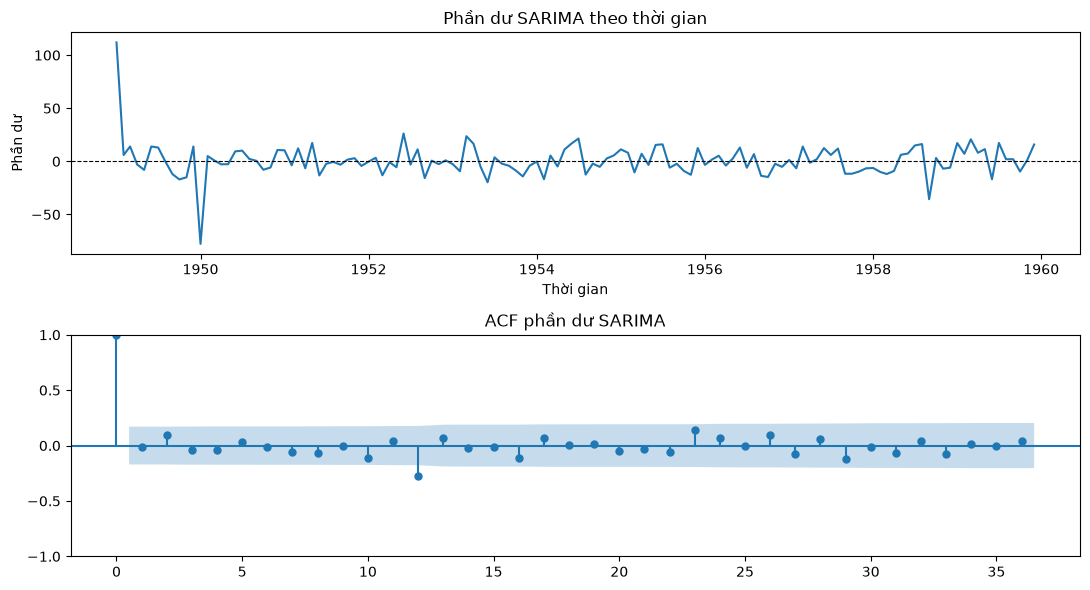

In [39]:
sarima_residuals = pd.Series(sarima_fit.resid).dropna()
ljung_box = acorr_ljungbox(sarima_residuals, lags=[12], model_df=2, return_df=True)
print("Kiểm định Ljung–Box trên phần dư SARIMA (lag 12):")
print(ljung_box.round(4).to_string())

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(sarima_residuals)
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set(title="Phần dư SARIMA theo thời gian", xlabel="Thời gian", ylabel="Phần dư")
plot_acf(sarima_residuals, lags=36, ax=axes[1])
axes[1].set_title("ACF phần dư SARIMA")
plt.tight_layout()
plt.show()

**Nhận xét 5.2:**
- **Ljung–Box (lag 12):** thống kê = 16,1454, p-value = **0,0955 > 0,05** → chưa bác bỏ H₀, phần dư **chưa có tự tương quan đáng kể**.
- **13 phần dư đầu không phản ánh sai số dự báo:** mô hình dùng d = 1 và D = 1 (s = 12) nên 13 quan sát đầu (1 + 12) chỉ dùng để khởi tạo. Phần dư của chúng lớn bất thường (điểm đầu tiên là 112, điểm thứ 13 là −78), nhìn rõ ở đầu đồ thị phần dư. Chúng cũng làm lag 12 của ACF phần dư (khoảng −0,27) vượt vùng tin cậy.
- **Bỏ 13 điểm đầu** (dòng `print` cuối cell trên): phần dư có Mean = 0,65 và Std = 10,45 (xấp xỉ 0 so với độ lệch chuẩn), Ljung–Box lag 12 cho p = 0,4504, không còn điểm nào bất thường.

### Nhận xét mục 5
**Chọn mô hình nào?** SARIMA(0,1,1)(0,1,1)₁₂, theo ACF/PACF và cấu trúc airline model (mục 5.1).

**Phần dư đã là nhiễu trắng chưa?** **Gần như đã là nhiễu trắng**: dao động quanh 0, Ljung–Box không bác bỏ H₀ (p = 0,0955; p = 0,4504 nếu bỏ các điểm khởi tạo). Mô hình đã giải thích được phần lớn tương quan trong dữ liệu.

## 6. Forecast và đánh giá SARIMA (MAE, RMSE)

**Yêu cầu**
- Dự báo 12 tháng của tập test (năm 1960) bằng mô hình SARIMA đã chọn.
- Đánh giá bằng MAE và RMSE; vẽ đồ thị Train, Test (thực tế) và Forecast.

**Câu hỏi cần trả lời**
- Dự báo có bám sát xu hướng và mùa vụ không?
- Sai lệch lớn nhất xảy ra ở đâu?
- MAE và RMSE nói lên điều gì?

MAE đo sai số tuyệt đối trung bình; RMSE nhạy hơn với sai số lớn. Đơn vị là nghìn hành khách.

### 6.1. Bảng dự báo và chỉ số đánh giá

In [40]:
sarima_forecast = sarima_fit.get_forecast(steps=len(test)).predicted_mean
sarima_forecast.index = test.index

def calculate_metrics(actual, predicted):
    errors = np.asarray(actual) - np.asarray(predicted)
    return float(np.mean(np.abs(errors))), float(np.sqrt(np.mean(errors**2)))


sarima_mae, sarima_rmse = calculate_metrics(test, sarima_forecast)
sarima_metrics = pd.DataFrame(
    {"MAE": [sarima_mae], "RMSE": [sarima_rmse]},
    index=[best_sarima_label],
)
print("Đánh giá SARIMA trên tập test (đơn vị: nghìn hành khách):")
print(sarima_metrics.round(2).to_string())

sarima_forecast_table = pd.DataFrame({"Thực tế": test, "Dự báo SARIMA": sarima_forecast})
print("\nDự báo SARIMA chi tiết:")
print(sarima_forecast_table.round(1).to_string())

Đánh giá SARIMA trên tập test (đơn vị: nghìn hành khách):
                                 MAE   RMSE
SARIMA(0, 1, 1)x(0, 1, 1, 12)  16.09  20.93

Dự báo SARIMA chi tiết:
            Thực tế  Dự báo SARIMA
Month                             
1960-01-01    417.0          422.8
1960-02-01    391.0          404.5
1960-03-01    419.0          466.8
1960-04-01    461.0          456.5
1960-05-01    472.0          479.7
1960-06-01    535.0          533.4
1960-07-01    622.0          607.5
1960-08-01    606.0          618.7
1960-09-01    508.0          522.6
1960-10-01    461.0          467.5
1960-11-01    390.0          422.2
1960-12-01    432.0          463.8


**Nhận xét 6.1:** **MAE = 16,09; RMSE = 20,93** (nghìn hành khách), tương đương khoảng 3,4% và 4,4% mức trung bình của tập test (476,2).

| Tháng | Thực tế | SARIMA | Sai lệch (dự báo − thực tế) |
|---|---|---|---|
| 01/1960 | 417 | 422,8 | +5,8 |
| 02/1960 | 391 | 404,5 | +13,5 |
| 03/1960 | 419 | 466,8 | **+47,8** |
| 04/1960 | 461 | 456,5 | −4,5 |
| 05/1960 | 472 | 479,7 | +7,7 |
| 06/1960 | 535 | 533,4 | −1,6 |
| 07/1960 | 622 | 607,5 | −14,5 |
| 08/1960 | 606 | 618,7 | +12,7 |
| 09/1960 | 508 | 522,6 | +14,6 |
| 10/1960 | 461 | 467,5 | +6,5 |
| 11/1960 | 390 | 422,2 | **+32,2** |
| 12/1960 | 432 | 463,8 | **+31,8** |

- **Sai lệch lớn nhất:** 03/1960 (+47,8), 11/1960 (+32,2) và 12/1960 (+31,8); chín tháng còn lại đều dưới 15.
- Dự báo **cao hơn thực tế ở 9/12 tháng** (sai lệch trung bình +12,7): mô hình hơi "lạc quan".

### 6.2. Đồ thị dự báo
Đồ thị gồm đường Train, Test (thực tế) và Forecast SARIMA trên 12 tháng cuối.

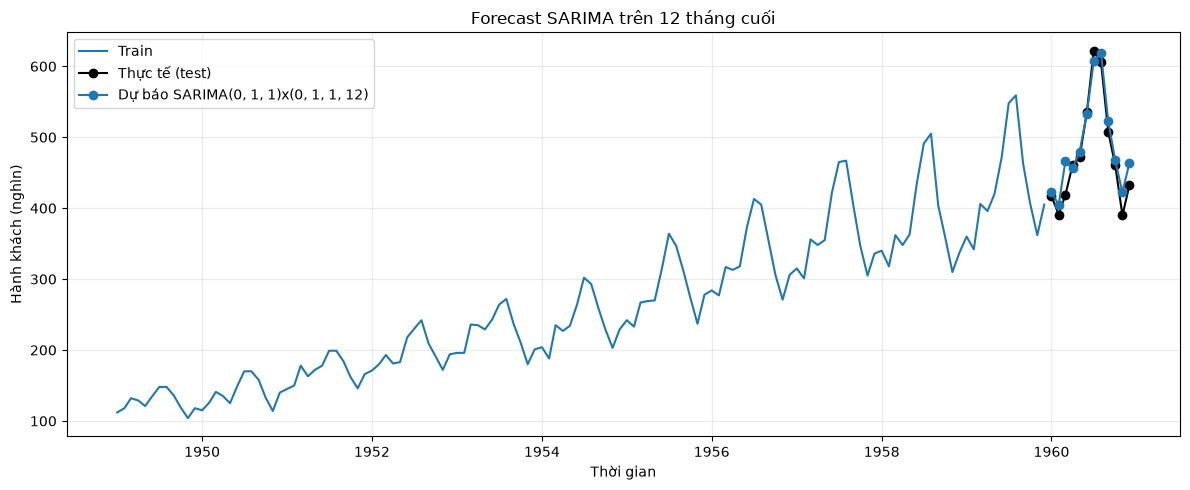

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index, train, label="Train", color="tab:blue")
ax.plot(test.index, test, label="Thực tế (test)", color="black", marker="o")
ax.plot(test.index, sarima_forecast, label=f"Dự báo {best_sarima_label}", marker="o")
ax.set(title="Forecast SARIMA trên 12 tháng cuối", xlabel="Thời gian", ylabel="Hành khách (nghìn)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Nhận xét 6.2:** Đường dự báo bám sát đường thực tế trong cả 12 tháng: tái hiện được **đỉnh mùa hè** (07 và 08/1960: dự báo 607,5 và 618,7, thực tế 622 và 606) và **đáy tháng 11**, đồng thời nối tiếp đúng mức và xu hướng tăng của đường train.

### Nhận xét mục 6
**Dự báo có bám sát xu hướng và mùa vụ không?** **Có.** Dự báo giữ đúng mức cao của năm 1960, có đỉnh vào tháng 7–8 và đáy vào tháng 11, sai lệch đa số chỉ vài đơn vị đến khoảng 15 nghìn hành khách.

**Sai lệch lớn nhất xảy ra ở đâu?** Ở **03/1960** (dự báo 466,8, thực tế 419; lệch +47,8). Tháng 3/1960 chỉ tăng 28 so với tháng 2 (391 → 419), trong khi năm 1959 tăng 64 (342 → 406), nên mô hình đi theo mẫu của các năm trước và dự báo quá cao. Cuối năm cũng lệch (11/1960: +32,2; 12/1960: +31,8) vì đáy tháng 11 thực tế sâu hơn dự báo.

**MAE và RMSE nói lên điều gì?** MAE = 16,09 nghĩa là trung bình mỗi tháng dự báo lệch khoảng 16 nghìn hành khách (3,4% mức trung bình năm 1960). RMSE (20,93) lớn hơn MAE vì nhạy với sai số lớn như 47,8 ở 03/1960; tỷ lệ RMSE/MAE ≈ 1,3 cho thấy sai số khá đồng đều, không có điểm ngoại lai quá nặng. RMSE chỉ khoảng 4,4% mức trung bình nên sai số ở mức nhỏ.

## 7. So sánh với ARIMA

**Yêu cầu**
- Fit ARIMA(1,1,1) (không có thành phần mùa vụ) trên cùng tập train, dự báo cùng 12 tháng test và so sánh với SARIMA.

**Câu hỏi cần trả lời**
- SARIMA tốt hơn ARIMA bao nhiêu?
- Vì sao ARIMA dự báo kém hơn?

### 7.1. So sánh SARIMA và ARIMA(1,1,1) trên cùng tập test

ARIMA(1, 1, 1): AIC = 1257.04; BIC = 1265.66

So sánh trên cùng tập test (đơn vị: nghìn hành khách):
                                 MAE   RMSE
SARIMA(0, 1, 1)x(0, 1, 1, 12)  16.09  20.93
ARIMA(1, 1, 1)                 66.24  91.23

Dự báo chi tiết:
            Thực tế  Dự báo SARIMA  Dự báo ARIMA
Month                                           
1960-01-01    417.0          422.8         433.5
1960-02-01    391.0          404.5         418.0
1960-03-01    419.0          466.8         426.4
1960-04-01    461.0          456.5         421.8
1960-05-01    472.0          479.7         424.3
1960-06-01    535.0          533.4         423.0
1960-07-01    622.0          607.5         423.7
1960-08-01    606.0          618.7         423.3
1960-09-01    508.0          522.6         423.5
1960-10-01    461.0          467.5         423.4
1960-11-01    390.0          422.2         423.5
1960-12-01    432.0          463.8         423.4

Mô hình có RMSE thấp nhất trên tập test: SARIMA(0, 1, 1)x(0, 1

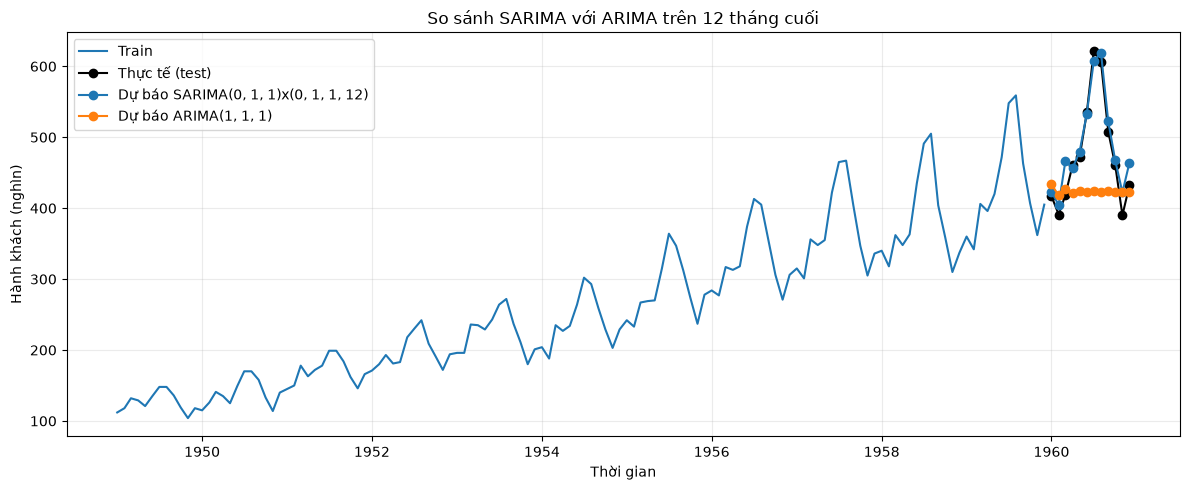

In [42]:
ARIMA_ORDER = (1, 1, 1)
arima_fit = ARIMA(train, order=ARIMA_ORDER, trend="n").fit()
arima_forecast = arima_fit.get_forecast(steps=len(test)).predicted_mean
arima_forecast.index = test.index

arima_mae, arima_rmse = calculate_metrics(test, arima_forecast)
results = pd.DataFrame(
    {
        "MAE": [sarima_mae, arima_mae],
        "RMSE": [sarima_rmse, arima_rmse],
    },
    index=[best_sarima_label, f"ARIMA{ARIMA_ORDER}"],
).sort_values("RMSE")
print(f"ARIMA{ARIMA_ORDER}: AIC = {arima_fit.aic:.2f}; BIC = {arima_fit.bic:.2f}")
print("\nSo sánh trên cùng tập test (đơn vị: nghìn hành khách):")
print(results.round(2).to_string())

forecast_table = pd.DataFrame(
    {"Thực tế": test, "Dự báo SARIMA": sarima_forecast, "Dự báo ARIMA": arima_forecast}
)
print("\nDự báo chi tiết:")
print(forecast_table.round(1).to_string())

best_test_model = results.index[0]
print(f"\nMô hình có RMSE thấp nhất trên tập test: {best_test_model}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index, train, label="Train", color="tab:blue")
ax.plot(test.index, test, label="Thực tế (test)", color="black", marker="o")
ax.plot(test.index, sarima_forecast, label=f"Dự báo {best_sarima_label}", marker="o")
ax.plot(test.index, arima_forecast, label=f"Dự báo ARIMA{ARIMA_ORDER}", marker="o")
ax.set(title="So sánh SARIMA với ARIMA trên 12 tháng cuối", xlabel="Thời gian", ylabel="Hành khách (nghìn)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Nhận xét 7.1:**

| Mô hình | MAE | RMSE |
|---|---|---|
| SARIMA(0,1,1)(0,1,1)₁₂ | 16,09 | 20,93 |
| ARIMA(1,1,1) | 66,24 | 91,23 |

- **ARIMA dự báo gần như một đường nằm ngang** (từ 418,0 đến 433,5, quanh mức 423), không có đỉnh mùa hè hay đáy cuối năm.
- Sai lệch lớn nhất ở đúng các **đỉnh mùa vụ**: 07/1960 (dự báo 423,7, thực tế 622; lệch −198,3), 08/1960 (−182,7) và 06/1960 (−112,0). ARIMA dự báo thấp hơn thực tế ở 8/12 tháng.
- AIC/BIC của hai mô hình (803,41 so với 1257,04) **không so sánh trực tiếp** được vì khác bậc sai phân; kết luận dựa trên sai số dự báo trên cùng tập test.

### Nhận xét mục 7
**SARIMA tốt hơn ARIMA bao nhiêu?** MAE giảm từ 66,24 xuống 16,09 (**giảm 75,7%**); RMSE giảm từ 91,23 xuống 20,93 (**giảm 77,1%**).

**Vì sao ARIMA dự báo kém hơn?** ARIMA(1,1,1) chỉ có sai phân thường (xử lý xu hướng) mà **không có thành phần mùa vụ**, nên không biết chuỗi lặp theo chu kỳ 12 tháng và chỉ dự báo một mức gần như không đổi. SARIMA thêm sai phân mùa vụ (D = 1) và thành phần MA mùa vụ nên tái hiện được chu kỳ, đặc biệt ở các đỉnh mùa hè là nơi ARIMA sai nhiều nhất.

## Kết luận

### Tóm tắt kết quả

| Bước | Kết quả |
|---|---|
| Dữ liệu | 144 quan sát hằng tháng (01/1949 đến 12/1960); Min 104, Max 622, Mean 280,30 |
| Xu hướng và mùa vụ | Xu hướng tăng (trung bình năm 126,7 → 476,2); mùa vụ chu kỳ 12 tháng, đỉnh tháng 7–8, đáy tháng 11; biên độ mùa vụ tăng dần |
| ADF chuỗi gốc | ADF statistic = 0,8154; p-value = 0,9919 → **không dừng** |
| Sai phân | d = 1, D = 1, s = 12: ADF statistic = −15,5956; p-value ≈ 1,86e-28 → **dừng** |
| ACF/PACF | Chỉ lag 1 nổi bật → p = 0, q = 1, P = 0; Q thử 0 và 1 |
| Mô hình chọn | **SARIMA(0,1,1)(0,1,1)₁₂** |
| Phần dư | Ljung–Box lag 12: p = 0,0955 (p = 0,4504 nếu bỏ 13 điểm khởi tạo) → gần như nhiễu trắng |
| SARIMA (12 tháng test) | MAE = 16,09; RMSE = 20,93 |
| ARIMA(1,1,1) | MAE = 66,24; RMSE = 91,23 |
| So sánh | SARIMA giảm MAE 75,7% và RMSE 77,1% so với ARIMA |

### Trả lời các câu hỏi
- **Chuỗi có xu hướng và mùa vụ không?** Có xu hướng tăng và mùa vụ chu kỳ 12 tháng (đỉnh tháng 7–8, đáy tháng 11).
- **Vì sao cần cả d = 1 và D = 1?** d = 1 loại xu hướng, D = 1 (s = 12) loại mùa vụ; chỉ kết hợp cả hai chuỗi mới dừng rõ ràng và ổn định (độ lệch chuẩn giảm từ 120,0 xuống 12,4).
- **ACF/PACF gợi ý bậc nào?** p = 0, q = 1, P = 0, Q = 0 hoặc 1; mô hình chọn là SARIMA(0,1,1)(0,1,1)₁₂.
- **Phần dư đã là nhiễu trắng chưa?** Gần như đã là nhiễu trắng (Ljung–Box không bác bỏ H₀).
- **SARIMA tốt hơn ARIMA bao nhiêu và vì sao?** Giảm khoảng 76–77% sai số, vì SARIMA có thành phần mùa vụ còn ARIMA thì không và chỉ dự báo một đường gần như phẳng.

### Giới hạn
- Đánh giá chỉ dựa trên **một** giai đoạn test 12 tháng; nên thử kiểm định cuốn chiếu (rolling-origin) trước khi dùng dự báo thực tế.
- Mùa vụ có dạng nhân (biên độ tăng theo mức chuỗi); có thể thử lấy log trước khi fit để ổn định phương sai.
- Chênh lệch AIC giữa các mô hình SARIMAX chỉ mang tính tham khảo (xem lưu ý ở mục 5.1).